# Busca em Grafo com A*

## Motivação

Em processadores embarcados, a multiplicação e divisão de numeros é uma operação muito custosa em termos de ciclos de clock. 

Por esta razão, compiladores utilizam otimizações para reduzir o custo de operações matematicas. 

No entanto, esta é uma tarefa complexa pois pode envolver a criação de muitas operações, o que aumentaria o tamanho do código e o tempo de execução. 

O objetivo deste trabalho é implementar o algoritmo de Busca A* para encontrar a sequência de operações mais curta para multiplicar ou dividir um número por uma constante, utilizando operações de soma, subtração e shift de bits.

Nesse problema, os pesos foram atribuídos da seguinte forma:
- Soma: peso 1;
- Subtração: peso 1;
- Divisão: peso 2;
- Multiplicação: peso 2;

## Heurística utilizada

A heurística estima quantas operações ainda faltam para chegar ao destino. Sendo $v$ o valor do estado atual e $d$ o destino, ela é definida por:

$$
h(v) =
\begin{cases}
0, & \text{se } v = d \\[4pt]
v - d, & \text{se } v > d \\[4pt]
\left\lfloor \log_2\!\left(\dfrac{d}{v}\right) \right\rfloor, & \text{se } v < d
\end{cases}
$$

- Se $v = d$: o destino já foi alcançado, então não falta nenhuma operação ($h = 0$).
- Se $v > d$: o valor está acima do destino, então a estimativa é voltar por meio de subtrações, uma por passo, resultando em $v - d$ operações.
- Se $v < d$: o valor está abaixo do destino, então a estimativa é crescer por meio de multiplicações por 2 (shift). Como $v \cdot 2^k = d$, o número de shifts é $k = \log_2(d/v)$. Por exemplo, de 256 até 1024, temos $k = \log_2(1024/256) = 2$ operações.

O A* escolhe sempre o estado com menor $f(n) = g(n) + h(n)$, em que $g(n)$ é o custo já percorrido e $h(n)$ é a estimativa do que falta. Dessa forma, a heurística direciona a busca para os estados mais próximos do destino, o que reduz o número de nós expandidos em comparação ao Dijkstra.

## Execução do código

### Imports

In [1]:
from sistema import executar
from sistema import plotar_grafo

### Execução da Busca

Valor de Início: 8
Valor de Destino: 1

Solução encontrada em 3 passos:
Nós expandidos: 10
Estado:    8 | Ação:   None | g:  0 | h:  7.0 | f:  7.0
Estado:    4 | Ação:   >> 1 | g:  2 | h:  3.0 | f:  5.0
Estado:    2 | Ação:   >> 1 | g:  4 | h:  1.0 | f:  5.0
Estado:    1 | Ação:    - 1 | g:  5 | h:  0.0 | f:  5.0
Número Total de Arestas geradas: 46


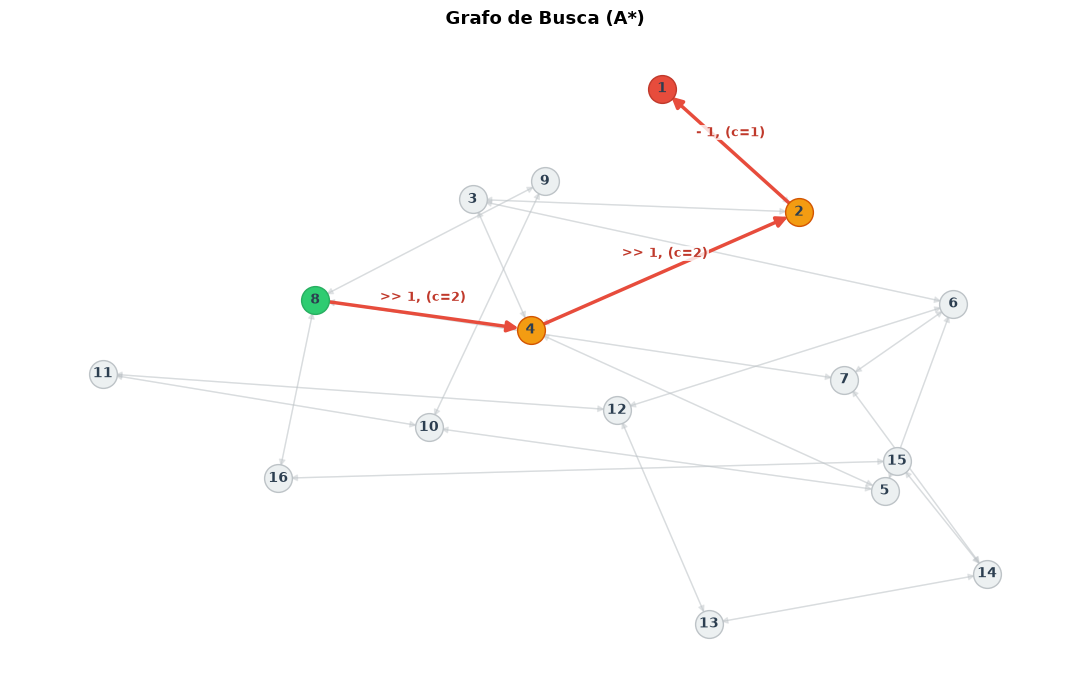

In [2]:
executar(8, 1)

### Interpretação do Resultado

O grafo gerou todas as operações possíveis dentro de um certo limite, para que não estoure o número de estados. Nesse caso, o limite é $2 * \text{max}(inicio, destino)$, ou seja o valor limite do estado (para representação visual no grafo) é $30$. Segundo o Algoritmo A*, o caminho encontrado, baseado na função $f(n) = g(n) + h(n)$, foi 8 -> 4 -> 2 -> 1, realizando as operações (shift, shift, subtração). É possível encontrar também outro caminho possível, como: 8 -> 7 -> 3 -> 1, com as operações (subtração, shift, shift).

## Comparação com o Algoritmo Dijkstra

Valor de Início: 8
Valor de Destino: 1

Solução encontrada em 3 passos:
Nós expandidos: 39
Estado:    8 | Ação:   None | g:  0 | h:  0.0 | f:  0.0
Estado:    7 | Ação:    - 1 | g:  1 | h:  0.0 | f:  1.0
Estado:    3 | Ação:   >> 1 | g:  3 | h:  0.0 | f:  3.0
Estado:    1 | Ação:   >> 1 | g:  5 | h:  0.0 | f:  5.0
Número Total de Arestas geradas: 46


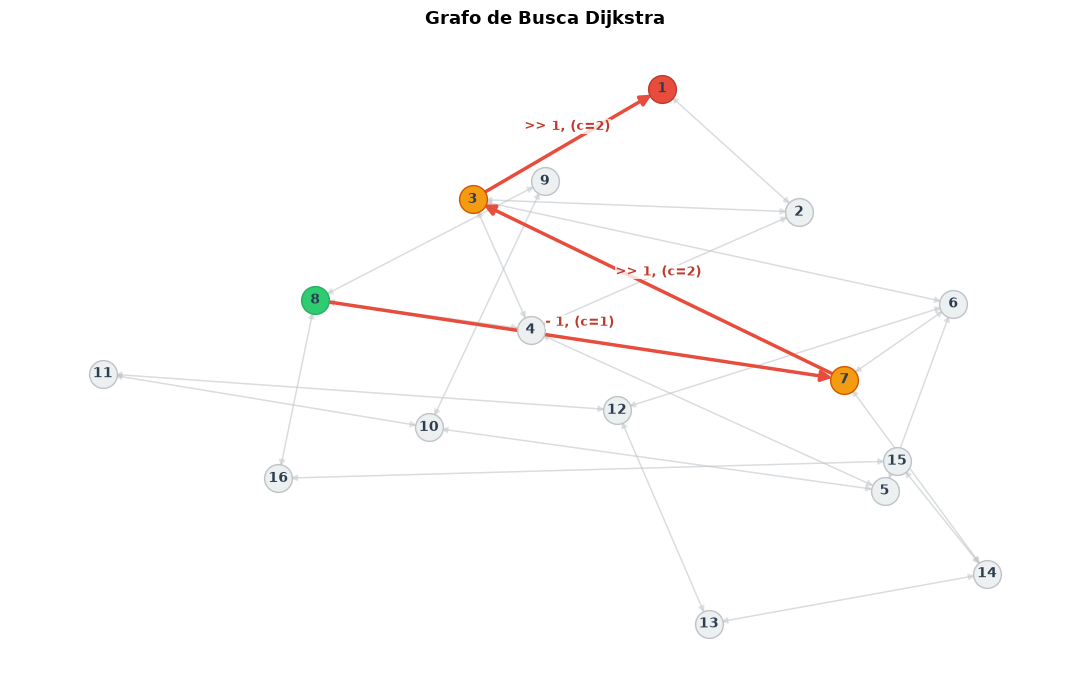

In [3]:
executar(8, 1, heuristica=False)

A diferença entre os caminhos ocorre porque os dois algoritmos escolhem o próximo estado a expandir de formas distintas. O Dijkstra considera apenas o custo acumulado $g(n)$, então expande todos os estados em ordem crescente de custo, sem nenhuma noção de direção. Quando existem vários caminhos com o mesmo custo total (como 8 -> 4 -> 2 -> 1 e 8 -> 7 -> 3 -> 1, ambos com custo 5), o caminho retornado depende apenas da ordem em que os estados foram inseridos na fila, ou seja, de um critério de desempate arbitrário. Já o A* utiliza $f(n) = g(n) + h(n)$, e a heurística $h(n)$ favorece os estados mais próximos do destino, o que o leva a seguir pelos shifts (8 -> 4 -> 2) em vez de explorar vizinhos como 9 ou 7. Dessa forma, ambos encontram um caminho de custo ótimo, mas o A* chega a ele expandindo muito menos nós (4 contra 22 neste exemplo).